In [1]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend, JoblibBackend

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/')
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils')
from general_plot_utils import assign_color

from hnn_core import duecker_ET_model, simulate_dipole
import matplotlib.pyplot as plt
import numpy as np

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/gamma'
os.makedirs(pathfig, exist_ok=True)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42


In [2]:
def net_block_ca(net_no_ca):
    # block Ca
    # 
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_HVA'] = 0

    return net_no_ca

In [3]:
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET.json')
params = hnn_core.read_params(params_fname)

In [4]:
seed = np.random.randint(0, 1e6)

net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.00275, 'L5_pyramidal': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 140.0, 'L5_pyramidal': 140.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=600, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

In [10]:
with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=600,bsl_cor='duecker', n_trials=10)

MPI will run 10 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from

In [6]:
# Keep gridspec for reference...
# from matplotlib import gridspec
# fig = plt.figure(constrained_layout=True, figsize=(12,6))
# gs = fig.add_gridspec(4,2)
# ax1 = fig.add_subplot(gs[:2, 1])
# ax2 = fig.add_subplot(gs[2:, 1])
# ax3 = fig.add_subplot(gs[:2, 0])
# ax4 = fig.add_subplot(gs[2:, 0])

# I = np.array(net.cell_response.spike_gids[0]) < 135
# gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
# times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
# colors = [assign_color(net, gid) for gid in gids]

# ax1.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')

# ax1.set_ylabel('L2/3 neurons')
# # ax1.set_yticks([0, 35, 135])
# # ax1.set_yticklabels([0, 35, 135])
# # ax1.set_xlim(0, 250)
# ax1.set_xticklabels([])
# ax1.invert_yaxis()
# ax1_2 = ax1.twinx()
# ax1_2.plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.75)

# I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
# gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
# times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
# colors = [assign_color(net, gid) for gid in gids]

# ax2.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
# ax2.set_ylabel('L5 neurons')
# # ax2.set_yticks([135, 170, 270])
# # ax2.set_yticklabels([135, 170, 270])
# # ax2.set_xlim(0, 250)
# # ax2.set_ylim([135, 270])
# ax2.invert_yaxis()
# ax2_2 = ax2.twinx()
# ax2_2.plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.75)

# ax3.plot(dpl[0].times, dpl[0].data['agg'], color='k')
# ax3.set_xlabel('time (ms)')

# freqs = np.arange(20., 100., 1.)
# dpl[0].plot_tfr_morlet(freqs, ax=ax4, n_cycles=7, show=False)



In [14]:
avg_dpl = hnn_core.average_dipoles(dpl)

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (10,) + inhomogeneous part.

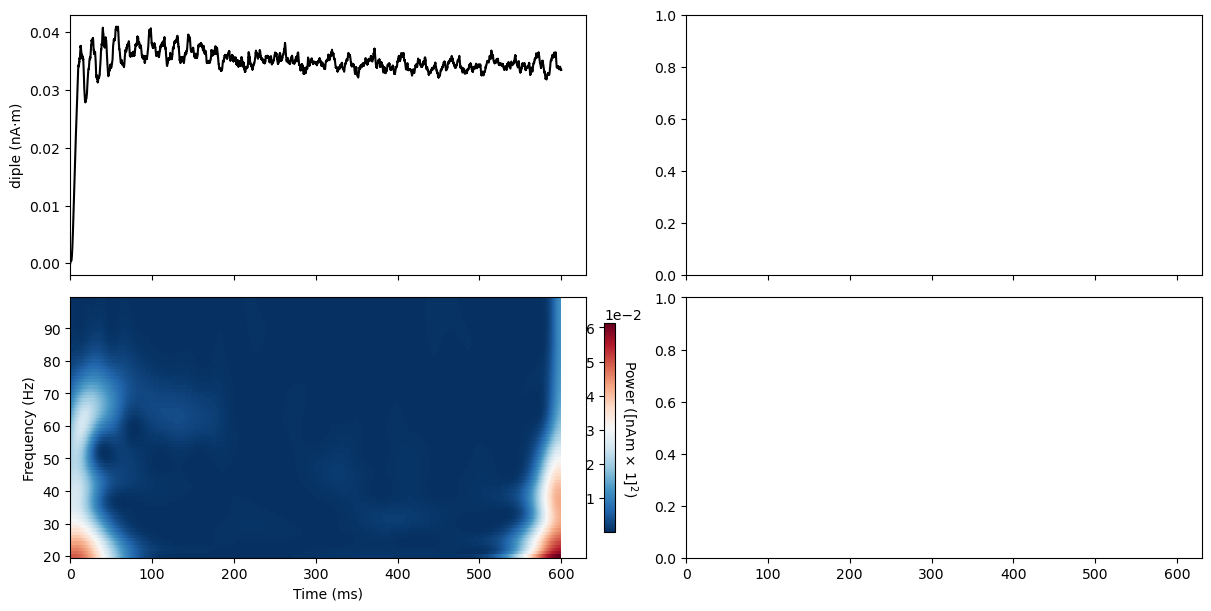

In [15]:
fig, ax = plt.subplots(2,2, figsize=(12, 6), constrained_layout=True, sharex=True)

ax[0,0].plot(dpl[0].times, avg_dpl.data['agg'], color='k')
ax[0,0].set_ylabel('diple (nA·m)')
freqs = np.arange(20., 100., 1.)
avg_dpl.plot_tfr_morlet(freqs, ax=ax[1,0], n_cycles=7, show=False, colormap='RdBu_r', colorbar_inside=False)

I = np.array(net.cell_response.spike_gids[0]) < 135
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
colors = [assign_color(net, gid) for gid in gids]

ax[0, 1].plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.25)
ax1_2 = ax[0, 1].twinx()

ax1_2.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
ax1_2.set_ylabel('L2/3 neurons')
ax1_2.set_xticklabels([])
ax1_2.invert_yaxis()


I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
colors = [assign_color(net, gid) for gid in gids]

ax[1,1].plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.25)
ax2_2 = ax[1,1].twinx()

ax2_2.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
ax2_2.set_ylabel('L5 neurons')
ax2_2.invert_yaxis()


ax[1,0].set_xlabel('time (ms)')
ax[1,0].set_xlim(0, 600)
ax[0,1].set_ylabel('L2/3 dipole (nA·m)')

ax[1,0].set_xticklabels(np.arange(0, 601, 100))
ax[1,1].set_xlabel('time (ms)')
ax[1,1].set_ylabel('L5 dipole(nA·m)')

ax[1,1].set_xlim(0, 600)

fig.savefig(op.join(pathfig, 'gamma_raster_dipole_tfr.png'), dpi=300)
fig.savefig(op.join(pathfig, 'gamma_raster_dipole_tfr.pdf'), dpi=300)

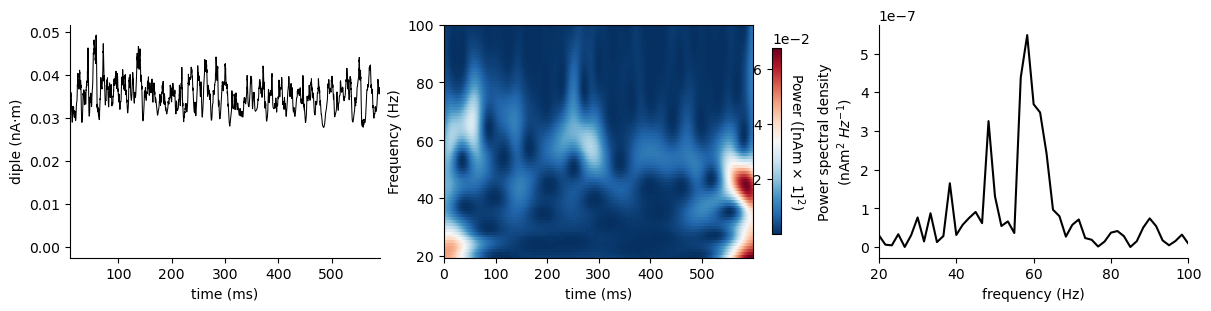

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)

ax[0].plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=0.75)
ax[0].set_ylabel('diple (nA·m)')
ax[0].set_xlabel('time (ms)')
# ax[0].set_ylim([0.02, 0.05])
# ax[0].set_yticks([0.02, 0.03, 0.04, 0.05])
ax[0].set_xlim([10, 590])
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
freqs = np.arange(20., 100., 1.)
dpl[0].plot_tfr_morlet(freqs, ax=ax[1], n_cycles=7, show=False, colormap='RdBu_r', colorbar_inside=False)
ax[1].set_xlabel('time (ms)')
ax[1].set_yticks([20, 40, 60, 80, 100])
dpl[0].plot_psd(ax=ax[2], fmin=20, fmax=100, show=False, color='k')
ax[2].spines['top'].set_visible(False)
ax[2].spines['right'].set_visible(False)
ax[2].set_xlabel('frequency (Hz)')

fig.savefig(op.join(pathfig, 'gamma_dipole_tfr_psd.png'), dpi=300)
fig.savefig(op.join(pathfig, 'gamma_dipole_tfr_psd.pdf'), dpi=300)

In [9]:
pathfig

'/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/gamma'